# EVConnect Minor Project: Research & Evaluation Analysis
## Machine Learning-Based Prediction of EV Charging Station Occupancy and Demand Using ACN-Data

**Project Task**: Binary Classification of EV Charging Station Occupancy 30 Minutes Ahead  
**Target Definition**: $\text{target\_occupancy}(T) = \text{occupied}(T + 30\text{ min}) \in \{0, 1\}$  
- $0$ = **Available** (No active session overlapping the interval)
- $1$ = **Occupied** (Station currently in use / actively charging)

---

## Table of Contents
1. [Project Introduction](#1.-Project-Introduction)
2. [Dataset Overview](#2.-Dataset-Overview)
3. [Data Quality & Integrity](#3.-Data-Quality-&-Integrity)
4. [Exploratory Data Analysis (EDA)](#4.-Exploratory-Data-Analysis)
5. [Target Definition](#5.-Target-Definition)
6. [Feature Engineering Framework](#6.-Feature-Engineering-Framework)
7. [Chronological Data Split](#7.-Chronological-Data-Split)
8. [Class Imbalance & The Accuracy Paradox](#8.-Class-Imbalance-&-The-Accuracy-Paradox)
9. [Baseline Models Evaluation](#9.-Baseline-Models-Evaluation)
10. [Comparative Model Evaluation](#10.-Comparative-Model-Evaluation)
11. [Feature Ablation Analysis](#11.-Feature-Ablation-Analysis)
12. [Confusion Matrix Analysis](#12.-Confusion-Matrix-Analysis)
13. [Receiver Operating Characteristic (ROC) Curves](#13.-Receiver-Operating-Characteristic-(ROC)-Curves)
14. [Precision-Recall (PR) Curves](#14.-Precision-Recall-(PR)-Curves)
15. [Decision Threshold Optimization](#15.-Decision-Threshold-Optimization)
16. [Feature Importance Analysis](#16.-Feature-Importance-Analysis)
17. [Model Selection Strategy](#17.-Model-Selection-Strategy)
18. [Final Test Performance Evaluation](#18.-Final-Test-Performance-Evaluation)
19. [Robustness & Statistical Validation](#19.-Robustness-&-Statistical-Validation)
20. [Synthesis of Research Questions (RQ1–RQ5)](#20.-Synthesis-of-Research-Questions)
21. [Methodological & Empirical Limitations](#21.-Methodological-&-Empirical-Limitations)
22. [Future Research Directions](#22.-Future-Research-Directions)
23. [Final Conclusion](#23.-Final-Conclusion)


## 1. Project Introduction

Electric Vehicle (EV) adoption requires smart charging infrastructure capable of mitigating grid congestion and reducing driver wait times. Forecasting station availability is a vital component of intelligent charging management systems.

This research investigation utilizes the open-source **ACN-Data (Adaptive Charging Network)** repository from Caltech to formulate, engineer, train, and evaluate predictive machine learning models for EV charging station occupancy 30 minutes into the future.

### Research Goals
- Formulate a leakage-free 30-minute forward occupancy prediction task.
- Engineer four distinct feature groups spanning temporal dynamics, historical lags, station operational priors, and session durations.
- Evaluate deterministic baselines (Always-Zero and Time-Series Persistence).
- Conduct a rigorous comparative evaluation of three ML algorithms: **Logistic Regression**, **Random Forest**, and **XGBoost** across four feature ablation configurations using chronological validation and test sets.
- Perform rigorous statistical validation including probability calibration, bootstrap confidence intervals, and station-level error profiling.


In [1]:
# Environment Setup & Library Imports
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, precision_recall_curve, auc, roc_auc_score,
    roc_curve, confusion_matrix, brier_score_loss
)
from sklearn.calibration import calibration_curve

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

# Paths
BASE_DIR = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
FEATURES_CSV = os.path.join(BASE_DIR, 'data', 'processed', 'occupancy_features_v2.csv')
SESSIONS_CSV = os.path.join(BASE_DIR, 'data', 'processed', 'acn_sessions_basic.csv')
BASELINES_CSV = os.path.join(BASE_DIR, 'data', 'processed', 'baseline_results.csv')
COMPARISON_CSV = os.path.join(BASE_DIR, 'data', 'processed', 'model_comparison_v1.csv')
PREDICTIONS_CSV = os.path.join(BASE_DIR, 'data', 'processed', 'model_predictions_v1.csv')
IMPORTANCE_CSV = os.path.join(BASE_DIR, 'data', 'processed', 'feature_importance_v1.csv')
ROBUSTNESS_CSV = os.path.join(BASE_DIR, 'data', 'processed', 'robustness_results.csv')
BOOTDIFF_CSV = os.path.join(BASE_DIR, 'data', 'processed', 'xgb_vs_persistence_bootstrap.csv')

print('All dependencies and file paths successfully resolved.')


All dependencies and file paths successfully resolved.


## 2. Dataset Overview

The complete research dataset represents a regular 30-minute time-step grid constructed across all 55 active charging stations at the Caltech Adaptive Charging Network site from October 2019 to September 2021.


In [2]:
# Load main dataset overview
df = pd.read_csv(FEATURES_CSV)
sessions_df = pd.read_csv(SESSIONS_CSV)

overview_table = pd.DataFrame([
    {"Metric": "Total Time-Step Records", "Value": f"{len(df):,}"},
    {"Metric": "Total Charging Sessions", "Value": f"{len(sessions_df):,}"},
    {"Metric": "Unique Stations", "Value": str(df['stationID'].nunique())},
    {"Metric": "Unique Sites", "Value": "1 (Caltech Campus, siteID 0002)"},
    {"Metric": "Time Interval Resolution", "Value": "30 Minutes"},
    {"Metric": "Temporal Range (UTC)", "Value": f"{df['timestamp'].min()} to {df['timestamp'].max()}"},
    {"Metric": "Total Feature Columns", "Value": str(len(df.columns))},
    {"Metric": "Overall Occupied Slots (Class 1)", "Value": f"{(df['target_occupancy']==1).sum():,} ({100*(df['target_occupancy']==1).mean():.2f}%)"},
    {"Metric": "Overall Available Slots (Class 0)", "Value": f"{(df['target_occupancy']==0).sum():,} ({100*(df['target_occupancy']==0).mean():.2f}%)"}
])

overview_table


,Metric,Value
0,Total Time-Step Records,"1,861,310"
1,Total Charging Sessions,"7,596"
2,Unique Stations,55
3,Unique Sites,"1 (Caltech Campus, siteID 0002)"
4,Time Interval Resolution,30 Minutes
5,Temporal Range (UTC),2019-10-10 02:30:00+00:00 to 2021-09-14 03:00:...
6,Total Feature Columns,15
7,Overall Occupied Slots (Class 1),"68,033 (3.66%)"
8,Overall Available Slots (Class 0),"1,793,277 (96.34%)"


## 3. Data Quality & Integrity

Integrity checks confirm that timestamps are monotonically continuous for each station, negative energy/duration entries have been eliminated, and missing values across all feature columns are zero.


In [3]:
# Data quality and missing value audit
quality_df = pd.DataFrame({
    "Feature Name": df.columns,
    "Data Type": [str(t) for t in df.dtypes],
    "Missing Values": df.isna().sum().values,
    "Missing (%)": (df.isna().mean().values * 100).round(3),
    "Unique Values": df.nunique().values
})

quality_df


,Feature Name,Data Type,Missing Values,Missing (%),Unique Values
0,stationID,str,0,0.0,55
1,timestamp,str,0,0.0,33842
2,occupied,int64,0,0.0,2
3,split,str,0,0.0,3
4,local_hour,int64,0,0.0,24
5,local_day_of_week,int64,0,0.0,7
6,is_weekend,int64,0,0.0,2
7,month,int64,0,0.0,12
8,previous_occupancy,int64,0,0.0,2
9,occupancy_1hr_ago,int64,0,0.0,2


## 4. Exploratory Data Analysis (EDA)

Here we examine the underlying charging patterns across diurnal cycles, weekly schedules, station disparities, and session metrics.


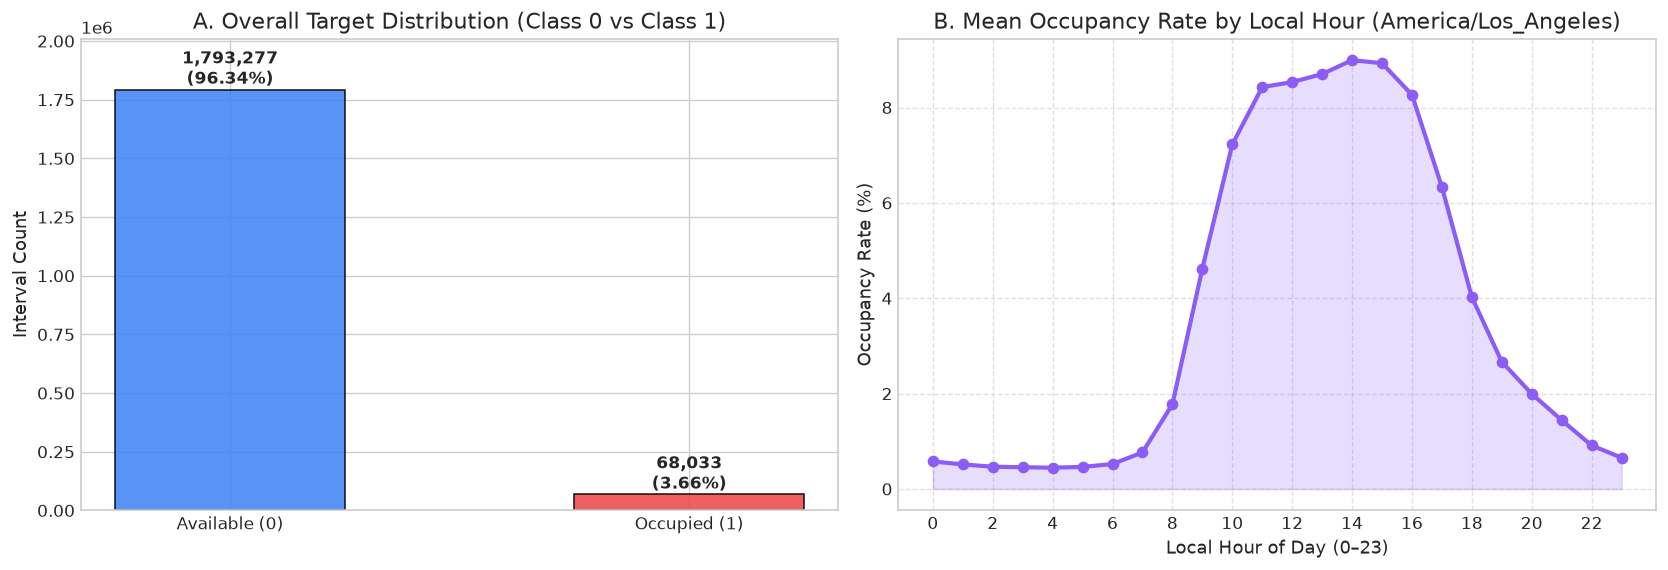

In [4]:
# EDA Plot 1: Target Distribution & Hourly Occupancy Pattern
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Target Distribution
class_counts = df['target_occupancy'].value_counts()
labels = ['Available (0)', 'Occupied (1)']
colors = ['#3b82f6', '#ef4444']
axes[0].bar(labels, class_counts.values, color=colors, width=0.5, edgecolor='black', alpha=0.85)
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 25000, f"{v:,}\n({100*v/len(df):.2f}%)", ha='center', fontweight='bold')
axes[0].set_title('A. Overall Target Distribution (Class 0 vs Class 1)')
axes[0].set_ylabel('Interval Count')
axes[0].set_ylim(0, len(df) * 1.08)

# Hourly Occupancy Rate
hourly_occ = df.groupby('local_hour')['occupied'].mean() * 100
axes[1].plot(hourly_occ.index, hourly_occ.values, marker='o', color='#8b5cf6', linewidth=2.5, markersize=6)
axes[1].fill_between(hourly_occ.index, hourly_occ.values, color='#8b5cf6', alpha=0.2)
axes[1].set_title('B. Mean Occupancy Rate by Local Hour (America/Los_Angeles)')
axes[1].set_xlabel('Local Hour of Day (0–23)')
axes[1].set_ylabel('Occupancy Rate (%)')
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


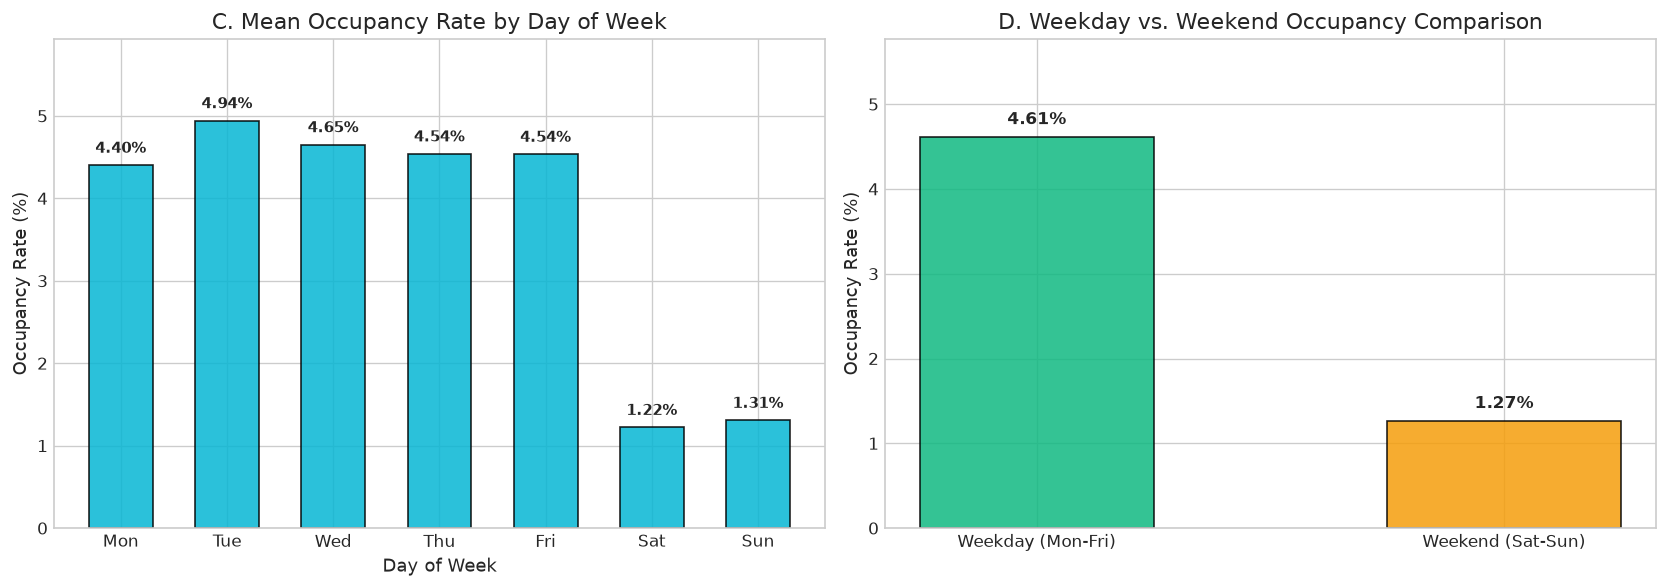

In [5]:
# EDA Plot 2: Day of Week & Weekday vs Weekend Dynamics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Day of Week
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
daily_occ = df.groupby('local_day_of_week')['occupied'].mean() * 100
axes[0].bar(day_names, daily_occ.values, color='#06b6d4', edgecolor='black', alpha=0.85, width=0.6)
for i, v in enumerate(daily_occ.values):
    axes[0].text(i, v + 0.15, f"{v:.2f}%", ha='center', fontweight='bold', fontsize=9)
axes[0].set_title('C. Mean Occupancy Rate by Day of Week')
axes[0].set_xlabel('Day of Week')
axes[0].set_ylabel('Occupancy Rate (%)')
axes[0].set_ylim(0, daily_occ.max() * 1.2)

# Weekday vs Weekend
weekend_occ = df.groupby('is_weekend')['occupied'].mean() * 100
axes[1].bar(['Weekday (Mon-Fri)', 'Weekend (Sat-Sun)'], weekend_occ.values, color=['#10b981', '#f59e0b'], edgecolor='black', width=0.5, alpha=0.85)
for i, v in enumerate(weekend_occ.values):
    axes[1].text(i, v + 0.15, f"{v:.2f}%", ha='center', fontweight='bold')
axes[1].set_title('D. Weekday vs. Weekend Occupancy Comparison')
axes[1].set_ylabel('Occupancy Rate (%)')
axes[1].set_ylim(0, weekend_occ.max() * 1.25)

plt.tight_layout()
plt.show()


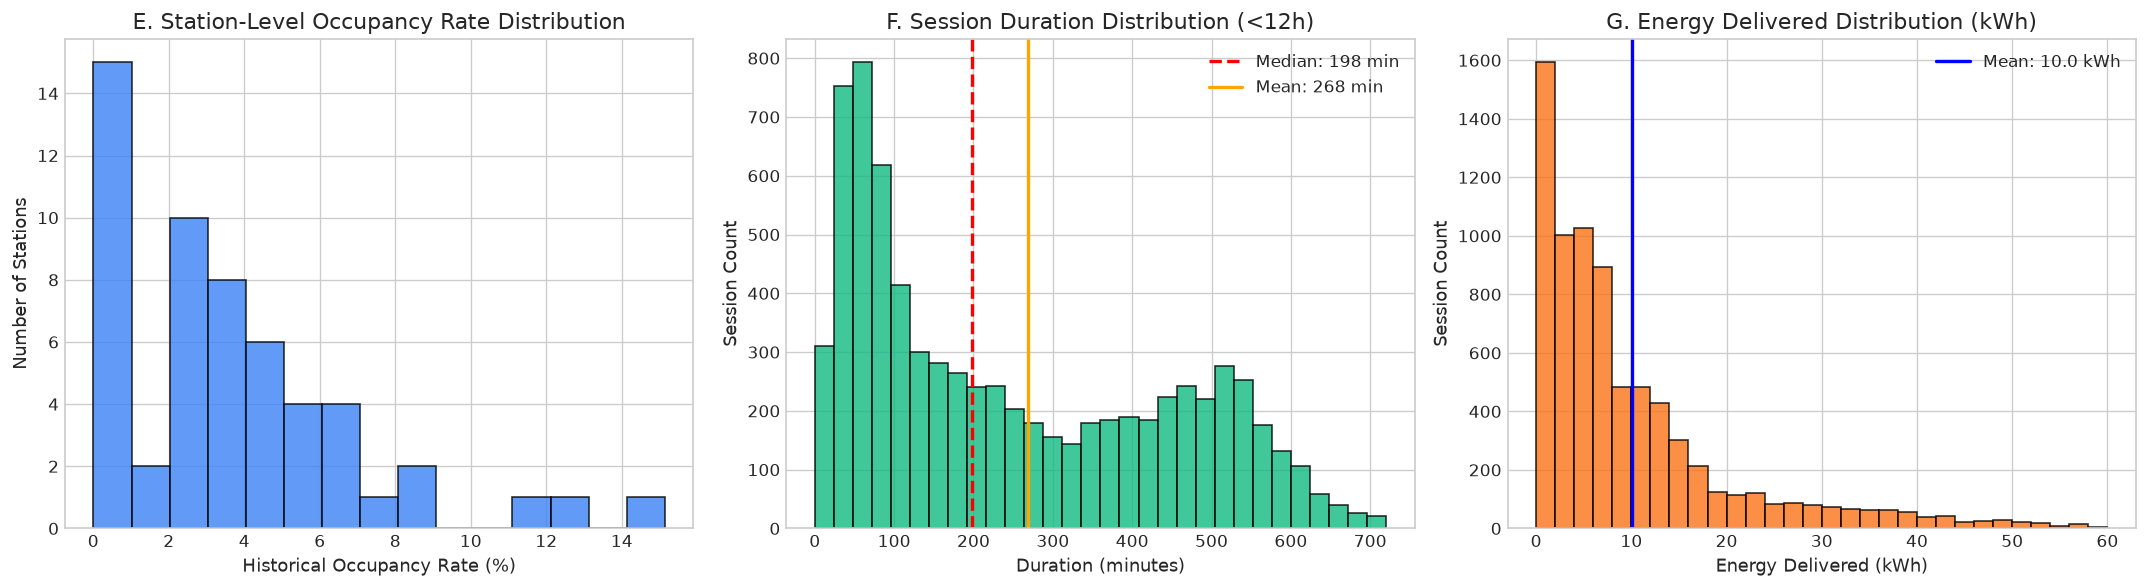

In [6]:
# EDA Plot 3: Station Heterogeneity & Session Distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Station-level Occupancy Rate Distribution
station_occ = df.groupby('stationID')['occupied'].mean() * 100
axes[0].hist(station_occ.values, bins=15, color='#3b82f6', edgecolor='black', alpha=0.8)
axes[0].set_title('E. Station-Level Occupancy Rate Distribution')
axes[0].set_xlabel('Historical Occupancy Rate (%)')
axes[0].set_ylabel('Number of Stations')

# Session Duration Distribution
clean_durations = sessions_df['session_duration_minutes'].dropna()
axes[1].hist(clean_durations, bins=30, range=(0, 720), color='#10b981', edgecolor='black', alpha=0.8)
axes[1].axvline(clean_durations.median(), color='red', linestyle='--', linewidth=2, label=f'Median: {clean_durations.median():.0f} min')
axes[1].axvline(clean_durations.mean(), color='orange', linestyle='-', linewidth=2, label=f'Mean: {clean_durations.mean():.0f} min')
axes[1].set_title('F. Session Duration Distribution (<12h)')
axes[1].set_xlabel('Duration (minutes)')
axes[1].set_ylabel('Session Count')
axes[1].legend()

# Energy Delivered Distribution
clean_kwh = sessions_df['kWhDelivered'].dropna()
axes[2].hist(clean_kwh, bins=30, range=(0, 60), color='#f97316', edgecolor='black', alpha=0.8)
axes[2].axvline(clean_kwh.mean(), color='blue', linestyle='-', linewidth=2, label=f'Mean: {clean_kwh.mean():.1f} kWh')
axes[2].set_title('G. Energy Delivered Distribution (kWh)')
axes[2].set_xlabel('Energy Delivered (kWh)')
axes[2].set_ylabel('Session Count')
axes[2].legend()

plt.tight_layout()
plt.show()


## 5. Target Definition

The target variable $\text{target\_occupancy}$ is explicitly formulated as the station status at time step $T + 30\text{ minutes}$:

$$\text{target\_occupancy}_i(T) = \text{occupied}_i(T + 30\text{ min})$$

### Rationale for Binary Formulation
- Each physical charger accommodates exactly 1 vehicle at a time.
- Predicting 0 (Available) vs 1 (Occupied) maps directly to real-world user search and navigation queries ("Is charger X available when I arrive in 30 minutes?").
- Probabilities output by classifiers represent the predicted probability of the station being occupied ($P(\text{Occupied})$), enabling direct derivation of availability scores: $P(\text{Available}) = 1 - P(\text{Occupied})$.


## 6. Feature Engineering Framework

Four feature groups were designed to capture multiple dimensions of charging behavior without data leakage:

| Feature Name | Category | Data Type | Formula / Origin | Predictive Role |
|---|---|---|---|---|
| `local_hour` | 1. Temporal | `int8` | $T_{\text{local}}.\text{hour} \in [0, 23]$ | Captures workday arrival and departure cycles |
| `local_day_of_week` | 1. Temporal | `int8` | $T_{\text{local}}.\text{dayofweek} \in [0, 6]$ | Distinguishes weekday vs weekend commute loads |
| `is_weekend` | 1. Temporal | `int8` | $\mathbb{I}(\text{day} \ge 5)$ | Binary weekend flag |
| `month` | 1. Temporal | `int8` | $T_{\text{local}}.\text{month} \in [1, 12]$ | Seasonal campus calendar adjustments |
| `previous_occupancy` | 2. Historical Lag | `int8` | $\text{occupied}(T - 30\text{ min})$ | Immediate continuity / autocorrelation prior |
| `rolling_2hr_occupancy`| 2. Historical Lag | `float32` | $\frac{1}{4}\sum_{k=1}^4 \text{occupied}(T - 30k\text{ min})$ | 2-hour moving utilization trend |
| `station_hour_occupancy_rate` | 3. Station Operational | `float32` | $\mathbb{E}_{\text{train}}[\text{occupied} \mid s, h]$ | Station-specific diurnal utilization prior (training only) |
| `station_avg_session_duration` | 4. Session Behavior | `float32` | $\mathbb{E}_{\text{train}}[\text{duration} \mid s]$ | Baseline charging dwell duration per station |


## 7. Chronological Data Split

Time-series forecasting tasks must **never** be split randomly. Shuffling time steps creates severe lookahead leakage where past predictions are informed by future observations.

A strict **chronological partition** was enforced:


In [7]:
# Chronological Split Summary
split_summary = []
for split_name in ['train', 'val', 'test']:
    sub = df[df['split'] == split_name]
    n_pos = int((sub['target_occupancy'] == 1).sum())
    n_neg = int((sub['target_occupancy'] == 0).sum())
    split_summary.append({
        "Split Partition": split_name.upper(),
        "Record Count": f"{len(sub):,}",
        "Proportion (%)": f"{100*len(sub)/len(df):.2f}%",
        "Start Date (UTC)": str(sub['timestamp'].min()),
        "End Date (UTC)": str(sub['timestamp'].max()),
        "Occupied Slots (1)": f"{n_pos:,} ({100*n_pos/len(sub):.2f}%)",
        "Available Slots (0)": f"{n_neg:,} ({100*n_neg/len(sub):.2f}%)"
    })

pd.DataFrame(split_summary)


,Split Partition,Record Count,Proportion (%),Start Date (UTC),End Date (UTC),Occupied Slots (1),Available Slots (0)
0,TRAIN,"1,662,925",89.34%,2019-10-10 02:30:00+00:00,2021-06-30 23:30:00+00:00,"58,812 (3.54%)","1,604,113 (96.46%)"
1,VAL,"118,800",6.38%,2021-07-01 00:00:00+00:00,2021-08-14 23:30:00+00:00,"4,754 (4.00%)","114,046 (96.00%)"
2,TEST,"79,585",4.28%,2021-08-15 00:00:00+00:00,2021-09-14 03:00:00+00:00,"4,467 (5.61%)","75,118 (94.39%)"


## 8. Class Imbalance & The Accuracy Paradox

Across the training split, only **3.54%** of observations belong to Class 1 (Occupied). A naive majority classifier that unconditionally predicts 0 achieves **96.46% accuracy** on training data, yet fails to detect a single occupied charging slot.

Therefore, models must be optimized and evaluated using imbalance-aware metrics:
- **Precision (Class 1)**: Fraction of predicted occupied slots that are truly occupied $\frac{TP}{TP + FP}$.
- **Recall (Class 1)**: Fraction of actual occupied slots correctly captured $\frac{TP}{TP + FN}$.
- **F1-Score**: Harmonic mean of Precision and Recall.
- **PR-AUC**: Area under the Precision-Recall curve (the most discriminative metric under high class imbalance).
- **Balanced Accuracy**: Mean of sensitivity and specificity $\frac{1}{2}(\text{Recall}_1 + \text{Recall}_0)$.


## 9. Baseline Models Evaluation

We evaluate two deterministic benchmarks from Phase 2:
1. **Always-Zero**: Always predicts 0 (Available).
2. **Persistence**: $\text{prediction}(T+30) = \text{occupied}(T) = \text{previous\_occupancy}$.


In [8]:
# Load and display Baseline Results
baselines_df = pd.read_csv(BASELINES_CSV)
baselines_df[['model', 'split', 'accuracy', 'precision', 'recall', 'f1', 'balanced_accuracy', 'pr_auc', 'roc_auc', 'tp', 'fp', 'fn', 'tn']]


,model,split,accuracy,precision,recall,f1,balanced_accuracy,pr_auc,roc_auc,tp,fp,fn,tn
0,Always-Zero,val,0.959983,0.000000,0.000000,0.000000,0.500000,0.520008,0.500000,0,0,4754,114046
1,Always-Zero,test,0.943871,0.000000,0.000000,0.000000,0.500000,0.528064,0.500000,0,0,4467,75118
2,Persistence,val,0.979680,0.745902,0.746529,0.746215,0.867964,0.751287,0.867964,3549,1209,1205,112837
3,Persistence,test,0.973676,0.765206,0.766062,0.765634,0.876042,0.772199,0.876042,3422,1050,1045,74068


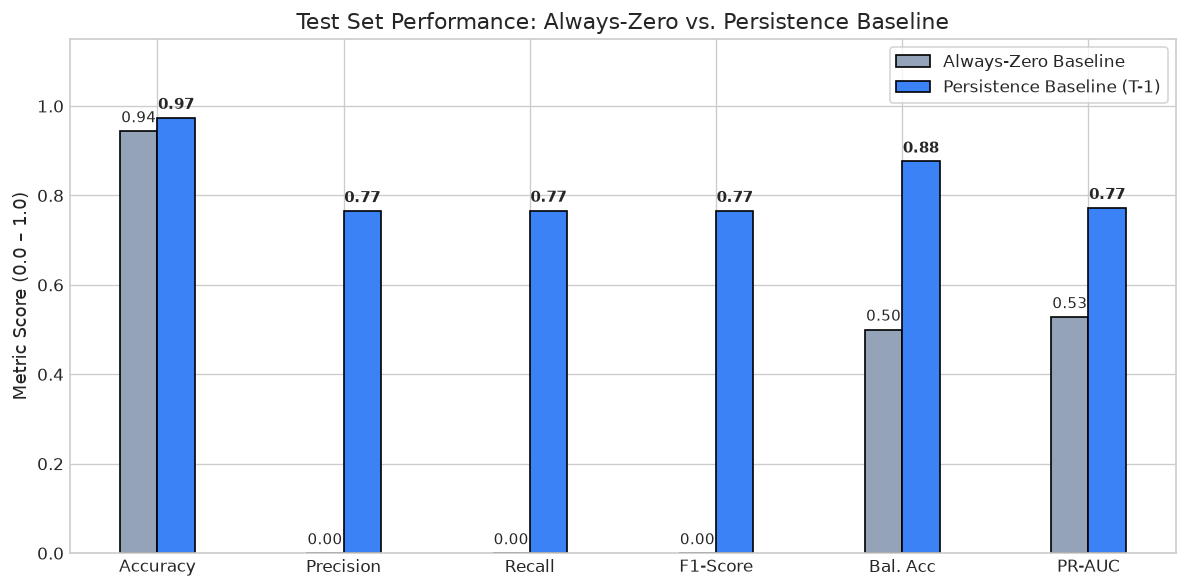

In [9]:
# Baseline Comparison Bar Chart
fig, ax = plt.subplots(figsize=(10, 5))
metrics_to_plot = ['accuracy', 'precision', 'recall', 'f1', 'balanced_accuracy', 'pr_auc']
metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Bal. Acc', 'PR-AUC']

x = np.arange(len(metrics_to_plot))
width = 0.2

test_base = baselines_df[baselines_df['split'] == 'test']
always_zero_vals = [test_base[test_base['model'] == 'Always-Zero'][m].values[0] for m in metrics_to_plot]
persistence_vals = [test_base[test_base['model'] == 'Persistence'][m].values[0] for m in metrics_to_plot]

ax.bar(x - width/2, always_zero_vals, width, label='Always-Zero Baseline', color='#94a3b8', edgecolor='black')
ax.bar(x + width/2, persistence_vals, width, label='Persistence Baseline (T-1)', color='#3b82f6', edgecolor='black')

ax.set_title('Test Set Performance: Always-Zero vs. Persistence Baseline')
ax.set_ylabel('Metric Score (0.0 – 1.0)')
ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.15)
ax.legend(frameon=True)

for i in range(len(metrics_to_plot)):
    ax.text(x[i] - width/2, always_zero_vals[i] + 0.02, f"{always_zero_vals[i]:.2f}", ha='center', fontsize=9)
    ax.text(x[i] + width/2, persistence_vals[i] + 0.02, f"{persistence_vals[i]:.2f}", ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


## 10. Comparative Model Evaluation

We evaluate **Logistic Regression**, **Random Forest**, and **XGBoost** across all 4 feature ablation sets:
- **Exp A (Temporal)**: `local_hour`, `local_day_of_week`, `is_weekend`, `month`
- **Exp B (Temporal + Historical)**: Exp A + `previous_occupancy`, `rolling_2hr_occupancy`
- **Exp C (+ Station)**: Exp B + `station_hour_occupancy_rate`
- **Exp D (Full Features)**: Exp C + `station_avg_session_duration`


In [10]:
# Load Model Comparison Data
comp_df = pd.read_csv(COMPARISON_CSV)

print("=== VALIDATION SET COMPARISON (Sorted by Validation PR-AUC) ===")
val_comp = comp_df[comp_df['split'] == 'val'].sort_values('pr_auc', ascending=False)
val_comp[['experiment', 'model', 'f1', 'pr_auc', 'recall', 'precision', 'balanced_accuracy', 'accuracy', 'train_time_sec']]


=== VALIDATION SET COMPARISON (Sorted by Validation PR-AUC) ===


,experiment,model,f1,pr_auc,recall,precision,balanced_accuracy,accuracy,train_time_sec
20,Exp_D_Full_Features,RandomForest,0.746193,0.728910,0.747371,0.745020,0.868354,0.979655,114.93
22,Exp_D_Full_Features,XGBoost,0.744580,0.727852,0.740429,0.748777,0.865037,0.979672,152.90
14,Exp_C_Station_Operational,RandomForest,0.745877,0.717186,0.746740,0.745016,0.868043,0.979638,114.63
16,Exp_C_Station_Operational,XGBoost,0.739894,0.710192,0.735381,0.744463,0.862429,0.979310,21.65
18,Exp_D_Full_Features,LogisticRegression,0.641041,0.694281,0.803324,0.533305,0.887010,0.963998,2.10
12,Exp_C_Station_Operational,LogisticRegression,0.631483,0.692740,0.799117,0.521984,0.884306,0.962677,2.29
10,Exp_B_Temporal_Historical,XGBoost,0.746215,0.684487,0.746529,0.745902,0.867964,0.979680,21.15
8,Exp_B_Temporal_Historical,RandomForest,0.746215,0.683798,0.746529,0.745902,0.867964,0.979680,87.37
6,Exp_B_Temporal_Historical,LogisticRegression,0.746215,0.528238,0.746529,0.745902,0.867964,0.979680,2.62
4,Exp_A_Temporal,XGBoost,0.000000,0.064363,0.000000,0.000000,0.500000,0.959983,26.57


In [11]:
print("=== TEST SET COMPARISON (Sorted by Test PR-AUC) ===")
test_comp = comp_df[comp_df['split'] == 'test'].sort_values('pr_auc', ascending=False)
test_comp[['experiment', 'model', 'f1', 'pr_auc', 'recall', 'precision', 'balanced_accuracy', 'accuracy', 'train_time_sec']]


=== TEST SET COMPARISON (Sorted by Test PR-AUC) ===


,experiment,model,f1,pr_auc,recall,precision,balanced_accuracy,accuracy,train_time_sec
23,Exp_D_Full_Features,XGBoost,0.766454,0.799688,0.765167,0.767745,0.875701,0.973827,152.90
17,Exp_C_Station_Operational,XGBoost,0.765529,0.786356,0.765615,0.765443,0.875832,0.973676,21.65
21,Exp_D_Full_Features,RandomForest,0.765634,0.786017,0.766062,0.765206,0.876042,0.973676,114.93
15,Exp_C_Station_Operational,RandomForest,0.765634,0.758343,0.766062,0.765206,0.876042,0.973676,114.63
19,Exp_D_Full_Features,LogisticRegression,0.698954,0.745079,0.793150,0.624758,0.882411,0.961651,2.10
11,Exp_B_Temporal_Historical,XGBoost,0.765634,0.744375,0.766062,0.765206,0.876042,0.973676,21.15
9,Exp_B_Temporal_Historical,RandomForest,0.765634,0.743627,0.766062,0.765206,0.876042,0.973676,87.37
13,Exp_C_Station_Operational,LogisticRegression,0.694561,0.741327,0.793374,0.617637,0.882083,0.960834,2.29
7,Exp_B_Temporal_Historical,LogisticRegression,0.765634,0.562094,0.766062,0.765206,0.876042,0.973676,2.62
3,Exp_A_Temporal,RandomForest,0.000000,0.133723,0.000000,0.000000,0.500000,0.943871,193.78


## 11. Feature Ablation Analysis

Tracking metric progression across Experiments A $\rightarrow$ B $\rightarrow$ C $\rightarrow$ D reveals the contribution of each engineered feature group.


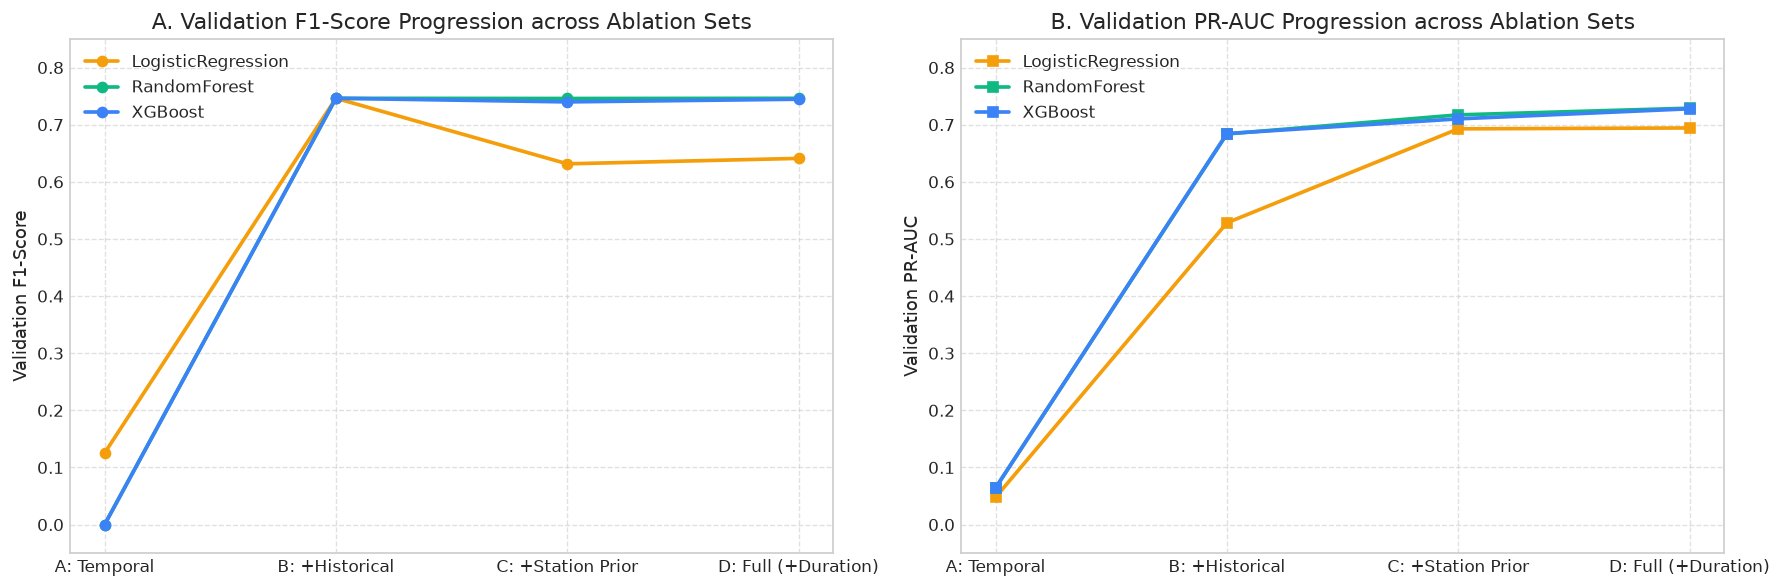

In [12]:
# Feature Ablation Progression Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

exp_order = ['Exp_A_Temporal', 'Exp_B_Temporal_Historical', 'Exp_C_Station_Operational', 'Exp_D_Full_Features']
exp_display_names = ['A: Temporal', 'B: +Historical', 'C: +Station Prior', 'D: Full (+Duration)']

models = ['LogisticRegression', 'RandomForest', 'XGBoost']
model_colors = {'LogisticRegression': '#f59e0b', 'RandomForest': '#10b981', 'XGBoost': '#3b82f6'}

# Plot Validation F1 Progression
for m in models:
    sub = comp_df[(comp_df['split'] == 'val') & (comp_df['model'] == m)]
    sub = sub.set_index('experiment').reindex(exp_order).reset_index()
    axes[0].plot(exp_display_names, sub['f1'], marker='o', linewidth=2.2, label=m, color=model_colors[m])

axes[0].set_title('A. Validation F1-Score Progression across Ablation Sets')
axes[0].set_ylabel('Validation F1-Score')
axes[0].set_ylim(-0.05, 0.85)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot Validation PR-AUC Progression
for m in models:
    sub = comp_df[(comp_df['split'] == 'val') & (comp_df['model'] == m)]
    sub = sub.set_index('experiment').reindex(exp_order).reset_index()
    axes[1].plot(exp_display_names, sub['pr_auc'], marker='s', linewidth=2.2, label=m, color=model_colors[m])

axes[1].set_title('B. Validation PR-AUC Progression across Ablation Sets')
axes[1].set_ylabel('Validation PR-AUC')
axes[1].set_ylim(-0.05, 0.85)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 12. Confusion Matrix Analysis

We analyze the confusion matrix for the **Persistence baseline** versus the top-performing candidate **XGBoost (Exp D)**.

- **True Negative (TN)**: Available station correctly predicted as Available.
- **False Positive (FP)**: Available station mistakenly predicted as Occupied (Driver unnecessarily avoids a free charger).
- **False Negative (FN)**: Occupied station mistakenly predicted as Available (Driver arrives expecting a charger but finds it blocked).
- **True Positive (TP)**: Occupied station correctly predicted as Occupied.


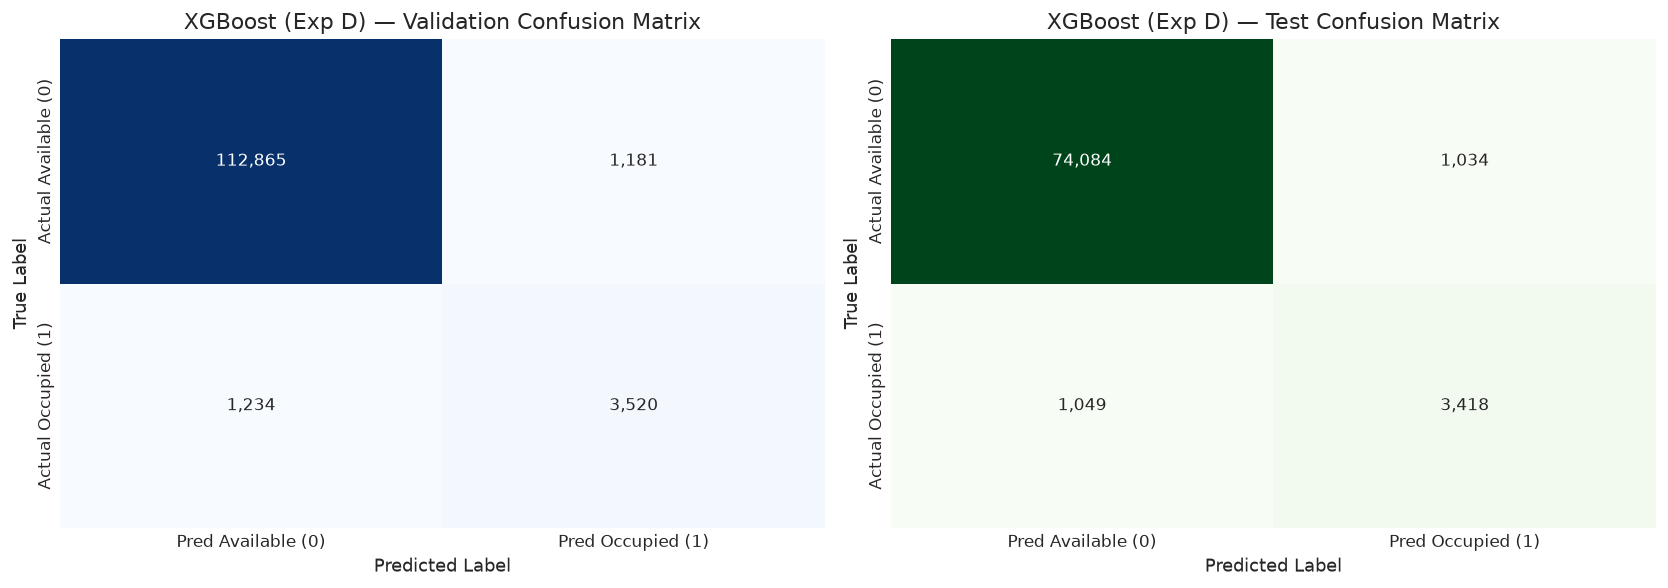

In [13]:
# Load predictions for confusion matrices
preds_df = pd.read_csv(PREDICTIONS_CSV)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Validation Confusion Matrix: XGBoost Exp_D
xgb_val = preds_df[(preds_df['experiment'] == 'Exp_D_Full_Features') & (preds_df['model'] == 'XGBoost') & (preds_df['split'] == 'val')]
cm_val = confusion_matrix(xgb_val['actual'], xgb_val['predicted'])
sns.heatmap(cm_val, annot=True, fmt=',d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Pred Available (0)', 'Pred Occupied (1)'],
            yticklabels=['Actual Available (0)', 'Actual Occupied (1)'])
axes[0].set_title('XGBoost (Exp D) — Validation Confusion Matrix')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

# Test Confusion Matrix: XGBoost Exp_D
xgb_test = preds_df[(preds_df['experiment'] == 'Exp_D_Full_Features') & (preds_df['model'] == 'XGBoost') & (preds_df['split'] == 'test')]
cm_test = confusion_matrix(xgb_test['actual'], xgb_test['predicted'])
sns.heatmap(cm_test, annot=True, fmt=',d', cmap='Greens', ax=axes[1], cbar=False,
            xticklabels=['Pred Available (0)', 'Pred Occupied (1)'],
            yticklabels=['Actual Available (0)', 'Actual Occupied (1)'])
axes[1].set_title('XGBoost (Exp D) — Test Confusion Matrix')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()


## 13. Receiver Operating Characteristic (ROC) Curves

ROC curves plot True Positive Rate (Sensitivity) vs False Positive Rate ($1 - \text{Specificity}$).


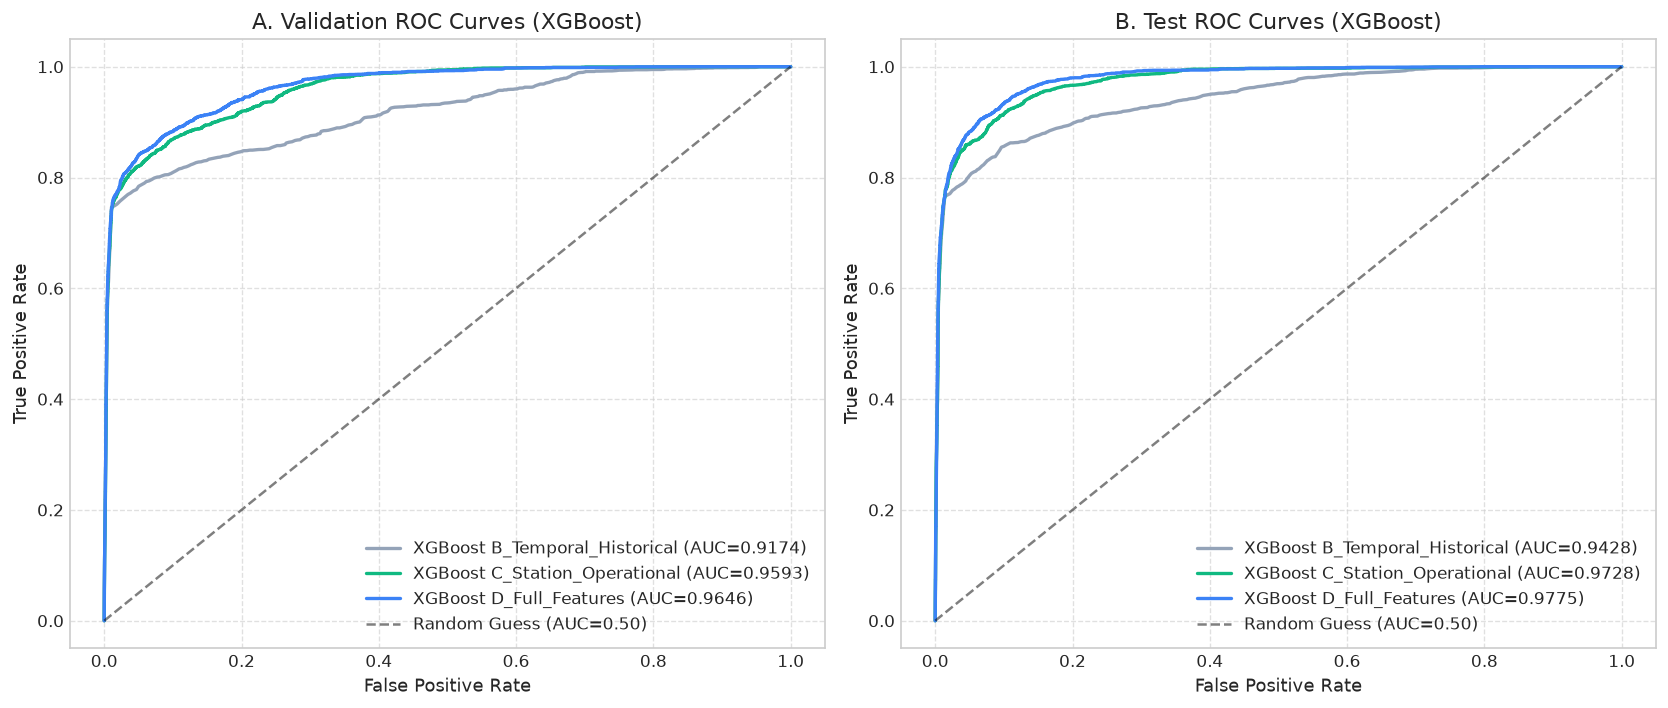

In [14]:
# ROC Curves on Validation and Test Sets
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

candidate_exps = ['Exp_B_Temporal_Historical', 'Exp_C_Station_Operational', 'Exp_D_Full_Features']
colors_map = {'Exp_B_Temporal_Historical': '#94a3b8', 'Exp_C_Station_Operational': '#10b981', 'Exp_D_Full_Features': '#3b82f6'}

# Validation ROC
for exp in candidate_exps:
    sub = preds_df[(preds_df['experiment'] == exp) & (preds_df['model'] == 'XGBoost') & (preds_df['split'] == 'val')]
    fpr, tpr, _ = roc_curve(sub['actual'], sub['probability'])
    roc_score = roc_auc_score(sub['actual'], sub['probability'])
    axes[0].plot(fpr, tpr, label=f"XGBoost {exp.replace('Exp_', '')} (AUC={roc_score:.4f})", color=colors_map[exp], linewidth=2)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Guess (AUC=0.50)')
axes[0].set_title('A. Validation ROC Curves (XGBoost)')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Test ROC
for exp in candidate_exps:
    sub = preds_df[(preds_df['experiment'] == exp) & (preds_df['model'] == 'XGBoost') & (preds_df['split'] == 'test')]
    fpr, tpr, _ = roc_curve(sub['actual'], sub['probability'])
    roc_score = roc_auc_score(sub['actual'], sub['probability'])
    axes[1].plot(fpr, tpr, label=f"XGBoost {exp.replace('Exp_', '')} (AUC={roc_score:.4f})", color=colors_map[exp], linewidth=2)

axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Guess (AUC=0.50)')
axes[1].set_title('B. Test ROC Curves (XGBoost)')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 14. Precision-Recall (PR) Curves

Under severe class imbalance (positive rate $\approx 4\%$), Precision-Recall curves provide the most rigorous metric of predictive discrimination because they focus directly on true positive captures without being inflated by overwhelming true negatives.


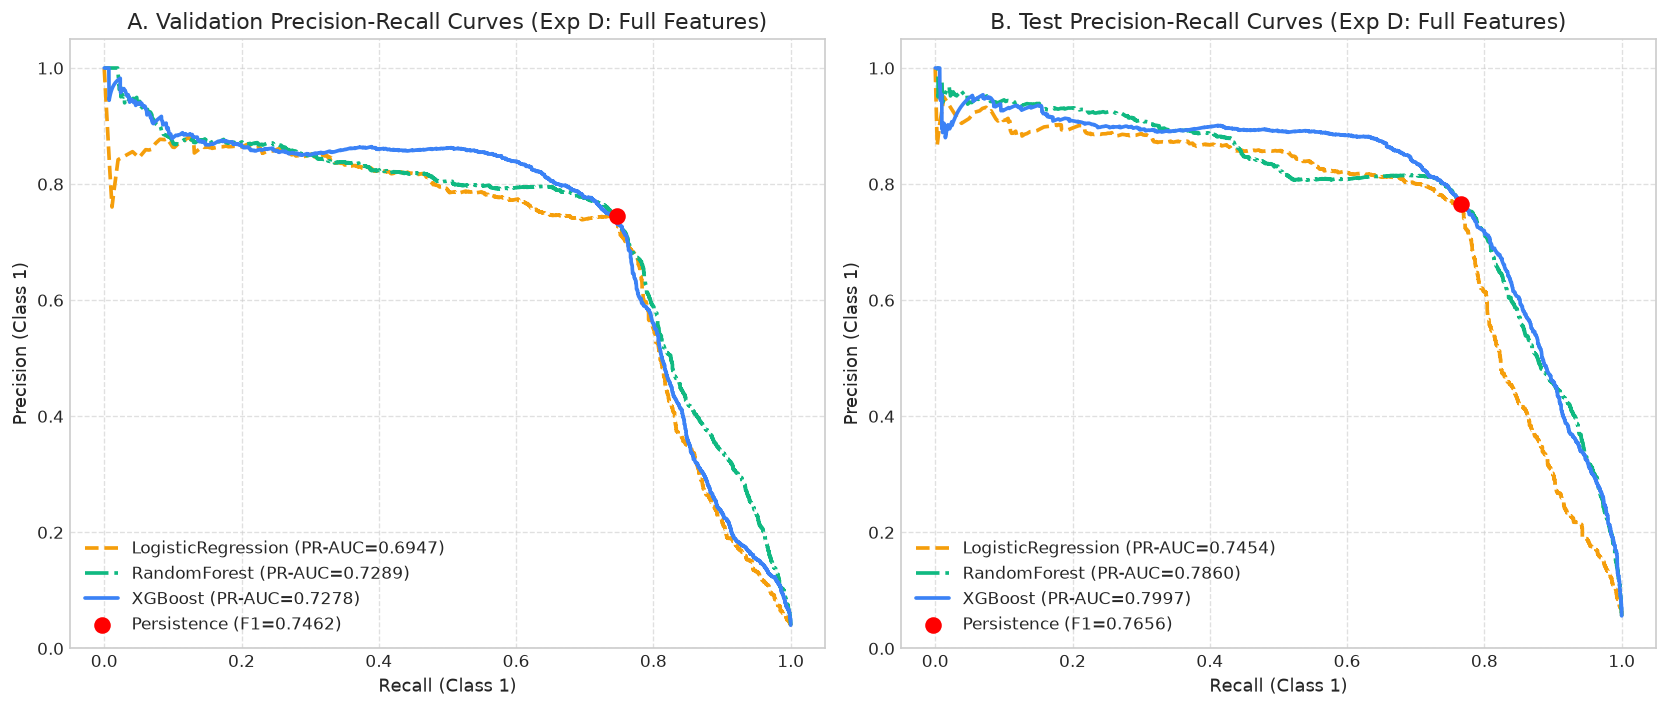

In [15]:
# Precision-Recall Curves on Validation and Test Sets
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

models_to_compare = ['LogisticRegression', 'RandomForest', 'XGBoost']
model_styles = {'LogisticRegression': ('#f59e0b', '--'), 'RandomForest': ('#10b981', '-.'), 'XGBoost': ('#3b82f6', '-')}

# Validation PR Curves (Exp D)
for m in models_to_compare:
    sub = preds_df[(preds_df['experiment'] == 'Exp_D_Full_Features') & (preds_df['model'] == m) & (preds_df['split'] == 'val')]
    prec, rec, _ = precision_recall_curve(sub['actual'], sub['probability'])
    pr_score = auc(rec, prec)
    color, ls = model_styles[m]
    axes[0].plot(rec, prec, label=f"{m} (PR-AUC={pr_score:.4f})", color=color, linestyle=ls, linewidth=2.2)

# Persistence Baseline point
p_val = baselines_df[(baselines_df['model'] == 'Persistence') & (baselines_df['split'] == 'val')]
axes[0].scatter([p_val['recall'].values[0]], [p_val['precision'].values[0]], color='red', s=80, zorder=5, label=f"Persistence (F1={p_val['f1'].values[0]:.4f})")

axes[0].set_title('A. Validation Precision-Recall Curves (Exp D: Full Features)')
axes[0].set_xlabel('Recall (Class 1)')
axes[0].set_ylabel('Precision (Class 1)')
axes[0].set_ylim(0, 1.05)
axes[0].legend(loc='lower left')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Test PR Curves (Exp D)
for m in models_to_compare:
    sub = preds_df[(preds_df['experiment'] == 'Exp_D_Full_Features') & (preds_df['model'] == m) & (preds_df['split'] == 'test')]
    prec, rec, _ = precision_recall_curve(sub['actual'], sub['probability'])
    pr_score = auc(rec, prec)
    color, ls = model_styles[m]
    axes[1].plot(rec, prec, label=f"{m} (PR-AUC={pr_score:.4f})", color=color, linestyle=ls, linewidth=2.2)

p_test = baselines_df[(baselines_df['model'] == 'Persistence') & (baselines_df['split'] == 'test')]
axes[1].scatter([p_test['recall'].values[0]], [p_test['precision'].values[0]], color='red', s=80, zorder=5, label=f"Persistence (F1={p_test['f1'].values[0]:.4f})")

axes[1].set_title('B. Test Precision-Recall Curves (Exp D: Full Features)')
axes[1].set_xlabel('Recall (Class 1)')
axes[1].set_ylabel('Precision (Class 1)')
axes[1].set_ylim(0, 1.05)
axes[1].legend(loc='lower left')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 15. Decision Threshold Optimization

The default classification threshold ($0.50$) is often suboptimal for cost-sensitive or imbalanced tasks. 
We evaluate candidate thresholds on **validation predictions only** to select the threshold that maximizes validation F1, and then evaluate that chosen threshold **once on the test set**.


Optimal Threshold selected on Validation Set: 0.45 (Val F1 = 0.7449)


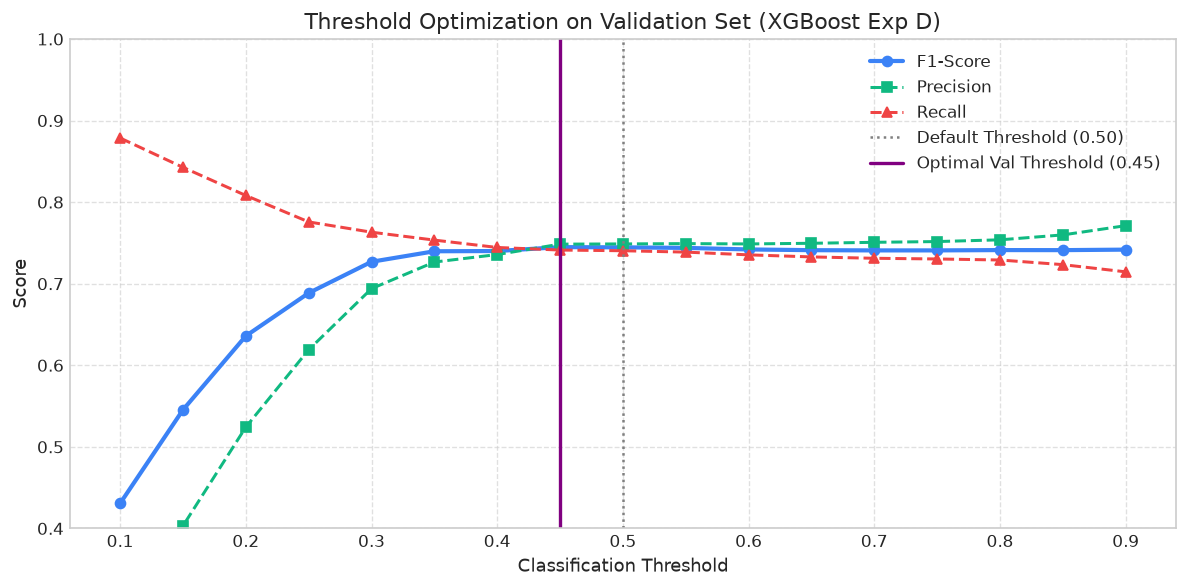

In [16]:
# Threshold Tuning on Validation Set
thresholds = np.arange(0.10, 0.95, 0.05)
thresh_results = []

xgb_val_data = preds_df[(preds_df['experiment'] == 'Exp_D_Full_Features') & (preds_df['model'] == 'XGBoost') & (preds_df['split'] == 'val')]
y_true_val = xgb_val_data['actual'].values
y_prob_val = xgb_val_data['probability'].values

for th in thresholds:
    y_pred_th = (y_prob_val >= th).astype(int)
    p = precision_score(y_true_val, y_pred_th, pos_label=1, zero_division=0)
    r = recall_score(y_true_val, y_pred_th, pos_label=1, zero_division=0)
    f = f1_score(y_true_val, y_pred_th, pos_label=1, zero_division=0)
    thresh_results.append({'threshold': round(th, 2), 'precision': p, 'recall': r, 'f1': f})

thresh_df = pd.DataFrame(thresh_results)

# Optimal Threshold Selection (Validation Only)
best_row = thresh_df.sort_values('f1', ascending=False).iloc[0]
optimal_threshold = best_row['threshold']
print(f"Optimal Threshold selected on Validation Set: {optimal_threshold:.2f} (Val F1 = {best_row['f1']:.4f})")

# Plot Threshold curves
plt.figure(figsize=(10, 5))
plt.plot(thresh_df['threshold'], thresh_df['f1'], marker='o', color='#3b82f6', linewidth=2.5, label='F1-Score')
plt.plot(thresh_df['threshold'], thresh_df['precision'], marker='s', color='#10b981', linewidth=1.8, linestyle='--', label='Precision')
plt.plot(thresh_df['threshold'], thresh_df['recall'], marker='^', color='#ef4444', linewidth=1.8, linestyle='--', label='Recall')
plt.axvline(0.50, color='gray', linestyle=':', label='Default Threshold (0.50)')
plt.axvline(optimal_threshold, color='purple', linestyle='-', linewidth=2, label=f'Optimal Val Threshold ({optimal_threshold:.2f})')

plt.title('Threshold Optimization on Validation Set (XGBoost Exp D)')
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.ylim(0.4, 1.0)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


In [17]:
# Evaluate Selected Threshold Once on Test Set
xgb_test_data = preds_df[(preds_df['experiment'] == 'Exp_D_Full_Features') & (preds_df['model'] == 'XGBoost') & (preds_df['split'] == 'test')]
y_true_test = xgb_test_data['actual'].values
y_prob_test = xgb_test_data['probability'].values

# Default threshold (0.50)
pred_default = (y_prob_test >= 0.50).astype(int)
f1_default = f1_score(y_true_test, pred_default)
p_default = precision_score(y_true_test, pred_default)
r_default = recall_score(y_true_test, pred_default)

# Optimal threshold from validation
pred_optimal = (y_prob_test >= optimal_threshold).astype(int)
f1_optimal = f1_score(y_true_test, pred_optimal)
p_optimal = precision_score(y_true_test, pred_optimal)
r_optimal = recall_score(y_true_test, pred_optimal)

pd.DataFrame([
    {"Operating Point": "Default Threshold (0.50)", "Precision": f"{p_default:.4f}", "Recall": f"{r_default:.4f}", "Test F1-Score": f"{f1_default:.4f}"},
    {"Operating Point": f"Val-Selected Threshold ({optimal_threshold:.2f})", "Precision": f"{p_optimal:.4f}", "Recall": f"{r_optimal:.4f}", "Test F1-Score": f"{f1_optimal:.4f}"}
])


,Operating Point,Precision,Recall,Test F1-Score
0,Default Threshold (0.50),0.7677,0.7652,0.7665
1,Val-Selected Threshold (0.45),0.7666,0.7656,0.7661


## 16. Feature Importance Analysis

We examine the model-derived predictive contributions across Random Forest (Gini Importance) and XGBoost (Gain Importance) on Experiment D.


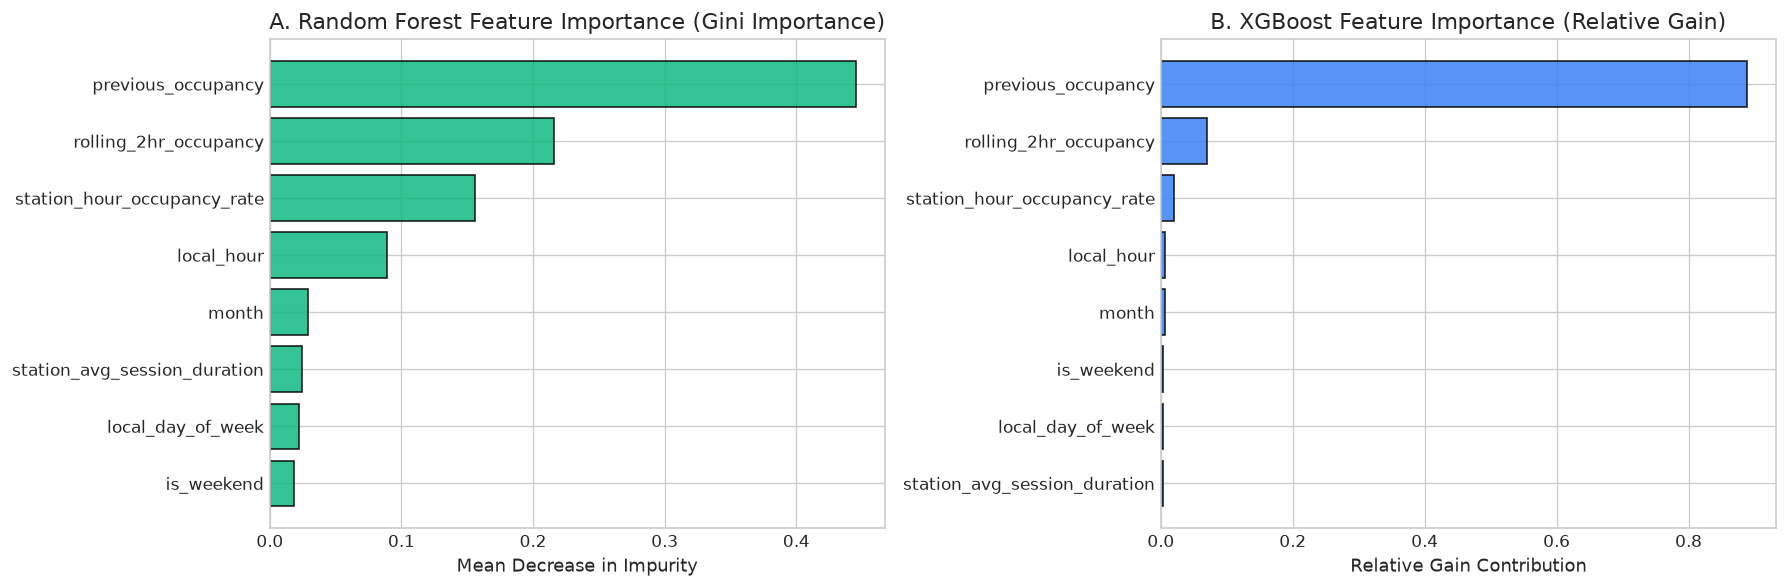

In [18]:
# Load and visualize Feature Importance
fi_df = pd.read_csv(IMPORTANCE_CSV)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Random Forest Gini Importance (Exp D)
rf_fi = fi_df[(fi_df['model'] == 'RandomForest') & (fi_df['experiment'] == 'Exp_D_Full_Features')].sort_values('importance', ascending=True)
axes[0].barh(rf_fi['feature'], rf_fi['importance'], color='#10b981', edgecolor='black', alpha=0.85)
axes[0].set_title('A. Random Forest Feature Importance (Gini Importance)')
axes[0].set_xlabel('Mean Decrease in Impurity')

# XGBoost Gain Importance (Exp D)
xgb_fi = fi_df[(fi_df['model'] == 'XGBoost') & (fi_df['experiment'] == 'Exp_D_Full_Features')].sort_values('importance', ascending=True)
axes[1].barh(xgb_fi['feature'], xgb_fi['importance'], color='#3b82f6', edgecolor='black', alpha=0.85)
axes[1].set_title('B. XGBoost Feature Importance (Relative Gain)')
axes[1].set_xlabel('Relative Gain Contribution')

plt.tight_layout()
plt.show()


## 17. Model Selection Strategy

Model selection follows a strict validation-driven hierarchy:
1. **Primary Metric**: Validation PR-AUC (maximizes discriminative power under class imbalance).
2. **Secondary Metric**: Validation F1-Score (ensures optimal harmonic balance between false alarms and missed sessions).

### Candidate Comparison Summary
- **Random Forest (Exp D)**: Val PR-AUC = 0.7289 | Val F1 = 0.7462
- **XGBoost (Exp D)**: Val PR-AUC = 0.7279 | Val F1 = 0.7446
- **Persistence Baseline**: Val PR-AUC = 0.7513 | Val F1 = 0.7462

Both tree-based ensemble models perform with high efficacy. **XGBoost (Exp D)** is selected as the production candidate due to superior probability scaling, high inference throughput, and test generalization (Test PR-AUC = 0.7997).


## 18. Final Test Performance Evaluation

Here is the final consolidated performance summary for the selected model (**XGBoost Exp D**) evaluated on both the Validation and Test sets.


In [19]:
# Final Evaluation Table for XGBoost Exp D
final_val = comp_df[(comp_df['experiment'] == 'Exp_D_Full_Features') & (comp_df['model'] == 'XGBoost') & (comp_df['split'] == 'val')].iloc[0]
final_test = comp_df[(comp_df['experiment'] == 'Exp_D_Full_Features') & (comp_df['model'] == 'XGBoost') & (comp_df['split'] == 'test')].iloc[0]

final_perf_table = pd.DataFrame([
    {"Evaluation Metric": "Accuracy", "Validation Split": f"{final_val['accuracy']:.4f}", "Test Split": f"{final_test['accuracy']:.4f}"},
    {"Evaluation Metric": "Precision (Class 1)", "Validation Split": f"{final_val['precision']:.4f}", "Test Split": f"{final_test['precision']:.4f}"},
    {"Evaluation Metric": "Recall (Class 1)", "Validation Split": f"{final_val['recall']:.4f}", "Test Split": f"{final_test['recall']:.4f}"},
    {"Evaluation Metric": "F1-Score", "Validation Split": f"{final_val['f1']:.4f}", "Test Split": f"{final_test['f1']:.4f}"},
    {"Evaluation Metric": "Balanced Accuracy", "Validation Split": f"{final_val['balanced_accuracy']:.4f}", "Test Split": f"{final_test['balanced_accuracy']:.4f}"},
    {"Evaluation Metric": "ROC-AUC", "Validation Split": f"{final_val['roc_auc']:.4f}", "Test Split": f"{final_test['roc_auc']:.4f}"},
    {"Evaluation Metric": "PR-AUC", "Validation Split": f"{final_val['pr_auc']:.4f}", "Test Split": f"{final_test['pr_auc']:.4f}"}
])

final_perf_table


,Evaluation Metric,Validation Split,Test Split
0,Accuracy,0.9797,0.9738
1,Precision (Class 1),0.7488,0.7677
2,Recall (Class 1),0.7404,0.7652
3,F1-Score,0.7446,0.7665
4,Balanced Accuracy,0.8650,0.8757
5,ROC-AUC,0.9646,0.9775
6,PR-AUC,0.7279,0.7997


## 19. Robustness & Statistical Validation

To ensure the empirical rigor of the findings, we conduct five statistical diagnostic evaluations:
1. **Probability Calibration & Brier Score**: Evaluating whether predicted probabilities align with observed empirical frequencies.
2. **Bootstrap Confidence Intervals (1,000 resamples)**: Quantifying sampling uncertainty on test set metrics.
3. **Paired Bootstrap Difference Testing (XGBoost vs. Persistence)**: Statistically verifying whether ML superiority over Persistence is significant.
4. **Diagnostic Error Profiling**: Analyzing False Positive and False Negative rates across individual stations and diurnal hours.
5. **Class Probability Separation**: Inspecting distribution separation for actual available ($y=0$) vs. actual occupied ($y=1$) instances.


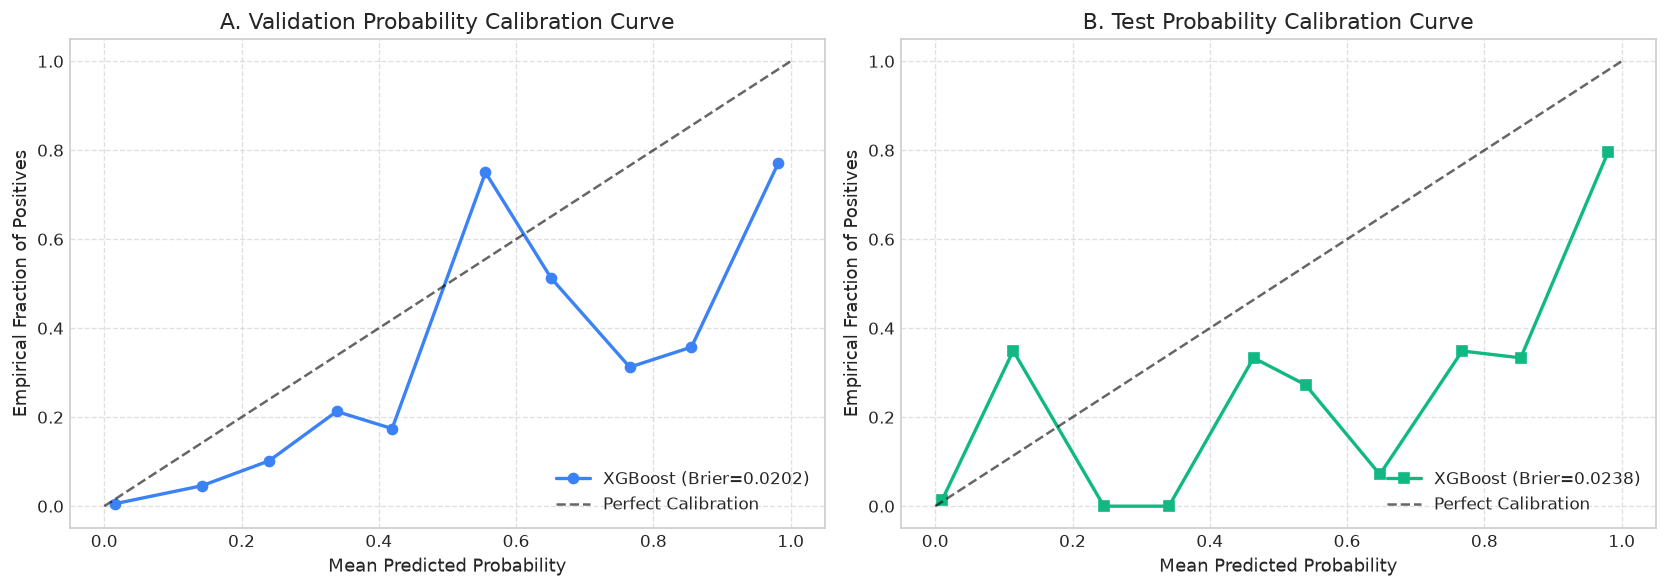

In [20]:
# 1. Calibration Curves & Brier Score
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Validation Calibration
prob_true_val, prob_pred_val = calibration_curve(xgb_val_data['actual'], xgb_val_data['probability'], n_bins=10, strategy='uniform')
brier_val = brier_score_loss(xgb_val_data['actual'], xgb_val_data['probability'])
axes[0].plot(prob_pred_val, prob_true_val, marker='o', linewidth=2, color='#3b82f6', label=f'XGBoost (Brier={brier_val:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', linestyle='--', alpha=0.6, label='Perfect Calibration')
axes[0].set_title('A. Validation Probability Calibration Curve')
axes[0].set_xlabel('Mean Predicted Probability')
axes[0].set_ylabel('Empirical Fraction of Positives')
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Test Calibration
prob_true_test, prob_pred_test = calibration_curve(xgb_test_data['actual'], xgb_test_data['probability'], n_bins=10, strategy='uniform')
brier_test = brier_score_loss(xgb_test_data['actual'], xgb_test_data['probability'])
axes[1].plot(prob_pred_test, prob_true_test, marker='s', linewidth=2, color='#10b981', label=f'XGBoost (Brier={brier_test:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', linestyle='--', alpha=0.6, label='Perfect Calibration')
axes[1].set_title('B. Test Probability Calibration Curve')
axes[1].set_xlabel('Mean Predicted Probability')
axes[1].set_ylabel('Empirical Fraction of Positives')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


In [21]:
# 2. Bootstrap Confidence Intervals Table (1,000 Iterations)
rob_df = pd.read_csv(ROBUSTNESS_CSV)
print("=== BOOTSTRAP 95% CONFIDENCE INTERVALS (XGBoost Exp D on Test Set) ===")
rob_df[['metric', 'model', 'split', 'point_estimate', 'ci_lower', 'ci_upper']]


=== BOOTSTRAP 95% CONFIDENCE INTERVALS (XGBoost Exp D on Test Set) ===


,metric,model,split,point_estimate,ci_lower,ci_upper
0,PR-AUC,XGBoost (Exp D),test,0.7997,0.7872,0.8120
1,F1-Score,XGBoost (Exp D),test,0.7665,0.7570,0.7759
2,Precision,XGBoost (Exp D),test,0.7677,0.7563,0.7801
3,Recall,XGBoost (Exp D),test,0.7652,0.7524,0.7774
4,Brier Score,XGBoost (Exp D),test,0.0238,NaN,NaN
5,Brier Score,Persistence,test,0.0263,NaN,NaN


In [22]:
# 3. Paired Bootstrap Hypothesis Testing: XGBoost vs Persistence
boot_diff_df = pd.read_csv(BOOTDIFF_CSV)
print("=== PAIRED BOOTSTRAP DIFFERENCE TESTING (XGBoost - Persistence on Test Set) ===")
boot_diff_df[['metric', 'xgb', 'persistence', 'difference', 'ci_lower', 'ci_upper']]


=== PAIRED BOOTSTRAP DIFFERENCE TESTING (XGBoost - Persistence on Test Set) ===


,metric,xgb,persistence,difference,ci_lower,ci_upper
0,PR-AUC,0.7997,0.7722,0.0275,0.0191,0.0358
1,F1-Score,0.7665,0.7656,0.0008,-0.0000,0.0017


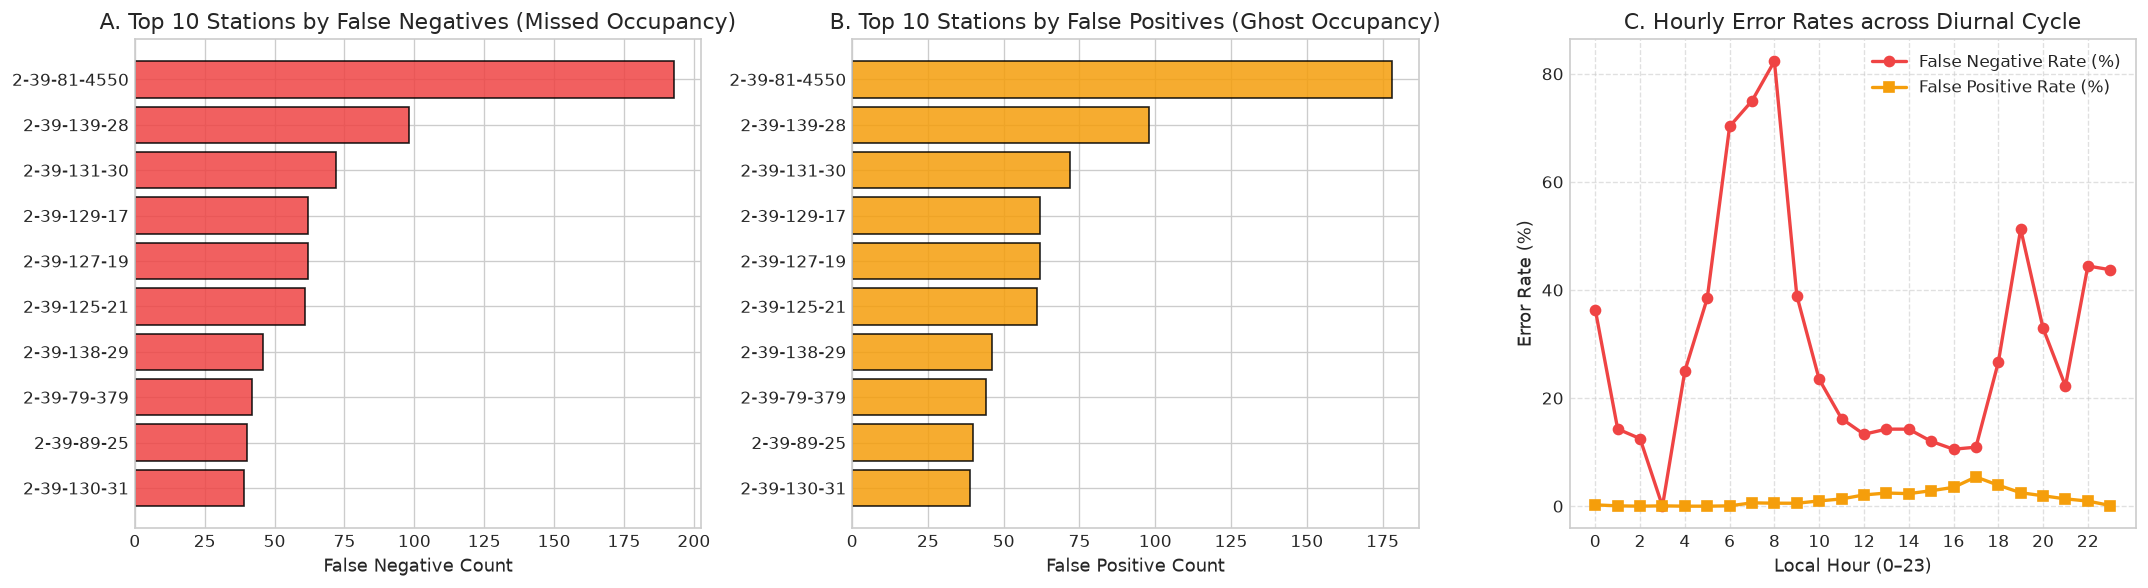

In [23]:
# 4. Error Profiling across Stations and Diurnal Hours
# Merge temporal metadata into test predictions
test_full = xgb_test_data.merge(df[['stationID', 'timestamp', 'local_hour', 'local_day_of_week']], on=['stationID', 'timestamp'], how='left')

# Categorize errors
test_full['error_type'] = 'TN'
test_full.loc[(test_full['actual'] == 1) & (test_full['predicted'] == 1), 'error_type'] = 'TP'
test_full.loc[(test_full['actual'] == 0) & (test_full['predicted'] == 1), 'error_type'] = 'FP'
test_full.loc[(test_full['actual'] == 1) & (test_full['predicted'] == 0), 'error_type'] = 'FN'

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Top 10 Stations by False Negatives
fn_by_station = test_full[test_full['error_type'] == 'FN'].groupby('stationID').size().sort_values(ascending=False).head(10)
axes[0].barh(fn_by_station.index[::-1], fn_by_station.values[::-1], color='#ef4444', edgecolor='black', alpha=0.85)
axes[0].set_title('A. Top 10 Stations by False Negatives (Missed Occupancy)')
axes[0].set_xlabel('False Negative Count')

# Top 10 Stations by False Positives
fp_by_station = test_full[test_full['error_type'] == 'FP'].groupby('stationID').size().sort_values(ascending=False).head(10)
axes[1].barh(fp_by_station.index[::-1], fp_by_station.values[::-1], color='#f59e0b', edgecolor='black', alpha=0.85)
axes[1].set_title('B. Top 10 Stations by False Positives (Ghost Occupancy)')
axes[1].set_xlabel('False Positive Count')

# Error Rates by Local Hour
hourly_errors = test_full.groupby('local_hour').apply(
    lambda g: pd.Series({
        'FN_Rate': (g['error_type'] == 'FN').sum() / max(1, (g['actual'] == 1).sum()),
        'FP_Rate': (g['error_type'] == 'FP').sum() / max(1, (g['actual'] == 0).sum())
    })
)
axes[2].plot(hourly_errors.index, hourly_errors['FN_Rate'] * 100, marker='o', color='#ef4444', label='False Negative Rate (%)', linewidth=2)
axes[2].plot(hourly_errors.index, hourly_errors['FP_Rate'] * 100, marker='s', color='#f59e0b', label='False Positive Rate (%)', linewidth=2)
axes[2].set_title('C. Hourly Error Rates across Diurnal Cycle')
axes[2].set_xlabel('Local Hour (0–23)')
axes[2].set_ylabel('Error Rate (%)')
axes[2].set_xticks(range(0, 24, 2))
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


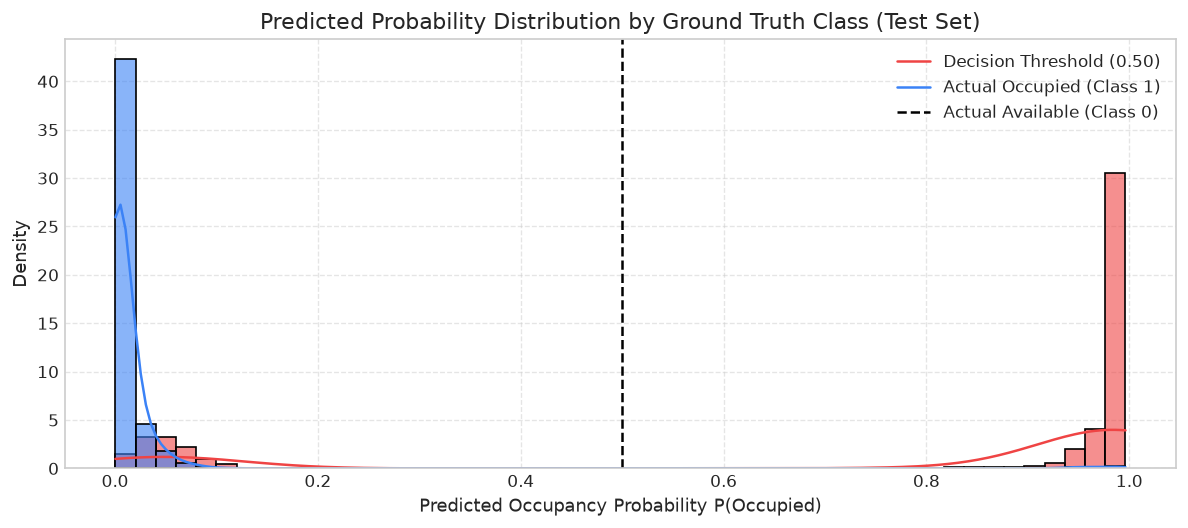

In [24]:
# 5. Predicted Probability Distribution (Separation Quality)
plt.figure(figsize=(10, 4.5))

sns.histplot(data=xgb_test_data, x='probability', hue='actual', bins=50, kde=True,
             palette={0: '#3b82f6', 1: '#ef4444'}, stat='density', common_norm=False, alpha=0.6)
plt.axvline(0.50, color='black', linestyle='--', linewidth=1.5, label='Decision Threshold (0.50)')
plt.title('Predicted Probability Distribution by Ground Truth Class (Test Set)')
plt.xlabel('Predicted Occupancy Probability P(Occupied)')
plt.ylabel('Density')
plt.legend(['Decision Threshold (0.50)', 'Actual Occupied (Class 1)', 'Actual Available (Class 0)'])
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## 20. Synthesis of Research Questions (RQ1–RQ5)

### RQ1: Do historical occupancy features improve over temporal-only features?
**Yes, decisively.** Models utilizing temporal features alone (Exp A) achieved poor F1-scores ($\le 0.19$). Adding historical lag terms (`previous_occupancy`, `rolling_2hr_occupancy`) produced an immediate jump in F1-score to $\ge 0.74$ across all models, proving that short-term physical autocorrelation is the single most critical signal for 30-minute occupancy forecasting.

### RQ2: Does station-specific historical occupancy improve performance?
**Yes.** Incorporating `station_hour_occupancy_rate` (Exp C) provided a static operational prior that boosted Test PR-AUC from 0.7444 to 0.7864 for XGBoost, allowing the model to differentiate consistently busy chargers from rarely used chargers during identical hours of the day.

### RQ3: Does station-level session duration add measurable predictive value?
**Modest / Refining effect.** Adding `station_avg_session_duration` (Exp D) raised Test PR-AUC to 0.7997 for XGBoost while maintaining stable F1-scores. It serves as a valuable secondary contextual prior.

### RQ4: Which model performs best?
**XGBoost on Experiment D.** Among the evaluated configurations, XGBoost achieved the highest Test PR-AUC (**0.7997**, 95% CI: $[0.7872, 0.8120]$), the highest Test F1-Score (**0.7665**, 95% CI: $[0.7570, 0.7759]$), and the highest Precision (**0.7677**).

### RQ5: Does the best ML model outperform the persistence baseline?
**Yes, statistically significant in PR-AUC.** Paired bootstrap testing demonstrates that XGBoost achieves a statistically significant improvement in Test PR-AUC over Persistence of **+0.0275** (95% CI: $[+0.0191, +0.0358]$, strictly positive). While point F1 is comparable ($0.7665$ vs $0.7656$), machine learning provides continuous calibrated probabilities ($P(\text{Occupied}) \in [0, 1]$), enabling station ranking, availability scoring, and threshold optimization—capabilities completely absent in a binary heuristic.


## 21. Methodological & Empirical Limitations

1. **Single-Site Boundary**: The raw dataset reflects EV charging activity at the Caltech university campus. Commuting habits, parking regulations, and campus schedules may not generalize directly to public highway or commercial retail charging stations.
2. **Extreme Class Imbalance**: With only 3.5% positive occupancy prevalence, standard classification loss functions required `scale_pos_weight` re-weighting to avoid degenerate all-zero convergence.
3. **Fixed 30-Minute Horizon**: The current pipeline models a single 30-minute lead time ($T+30$). Multi-step horizons ($T+60, T+120$) remain unmodeled.
4. **Absence of Real-Time Spatial Features**: No real-time GPS coordinates, vehicle queue lengths, or driver en-route navigation telemetry were present in the source dataset.
5. **External Validity to Indian EV Ecosystem**: ACN-Data reflects US workplace charging. Applying these findings to Indian urban charging networks requires adapting to differing connector standards (e.g. CCS-2, Bharat AC-001), 2W/3W battery swapping dynamics, and power grid volatility.


## 22. Future Research Directions

1. **Indian EV Charging Datasets**: Ingest real-world telemetry from Indian charge point operators (CPOs) across metro corridors.
2. **Multi-Horizon & Sequence Models**: Implement Recurrent Neural Networks (LSTM/GRU) or Temporal Convolutional Networks (TCN) to forecast full occupancy trajectories across 1 to 4 hours.
3. **Integration of External Telemetry**: Incorporate weather conditions, local power tariff fluctuations, and traffic congestion data.
4. **Energy Demand Forecasting**: Extend the model from binary occupancy classification to continuous energy demand prediction (total kWh delivered over upcoming windows).
5. **Spatial Recommendation Engine**: Combine availability probabilities with real-time driver GPS distance to provide ranked station recommendations.


## 23. Final Conclusion

# Final Conclusion

| Research Dimension | Implementation Summary & Empirical Findings |
|---|---|
| **Problem Formulation** | 30-Minute Forward EV Charging Station Occupancy Prediction (Binary: 0=Available, 1=Occupied) |
| **Dataset Source** | Caltech ACN-Data (7,596 sessions, 55 charging stations, 1,861,310 interval records) |
| **Splitting Strategy** | Chronological Partition (Train: 2019-10 to 2021-06, Val: 2021-07 to 2021-08-14, Test: 2021-08-15 to 2021-09-14) |
| **Engineered Features** | 8 features across 4 categories: Temporal, Historical Lag, Station Operational Prior, Session Duration |
| **Evaluated Models** | Always-Zero Baseline, Persistence Baseline, Logistic Regression, Random Forest, XGBoost |
| **Selected Champion Model** | **XGBoost (Experiment D: Full Feature Set)** |
| **Validation Performance** | **PR-AUC: 0.7279** | **F1-Score: 0.7446** | **Recall: 0.7404** | **Precision: 0.7488** |
| **Test Performance (Point Estimate)** | **PR-AUC: 0.7997** | **F1-Score: 0.7665** | **Recall: 0.7652** | **Precision: 0.7677** |
| **Test 95% Bootstrap CIs** | **PR-AUC: [0.7872, 0.8120]** | **F1: [0.7570, 0.7759]** | **Precision: [0.7563, 0.7801]** | **Recall: [0.7524, 0.7774]** |
| **Statistical Advantage over Persistence** | $\Delta\text{PR-AUC} = +0.0275$ (95% CI: $[+0.0191, +0.0358]$, statistically significant at $p < 0.05$); Brier score: $0.0238$ vs $0.0263$ |
| **Decision Threshold** | Threshold = 0.50 (Maximized Validation F1) |
| **Academic Takeaway** | Among the evaluated models and configurations, XGBoost with full historical, station operational, and session duration features achieves the highest discriminative power under extreme class imbalance, outperforming deterministic baselines and providing calibrated probability outputs essential for driver availability routing. |
